# Column audit: which columns are demand said twice

The demand forecast trains on `data/processed/cleaned_weather_carbon.csv`. It has 65 columns. Some of them are the answer in disguise, and some are another column written a second time. This notebook finds both kinds from the data, then shows what `src/column_audit.py` keeps.

- **Same-hour restatements of demand.** The fuel megawatthours are this hour's supply, and supply has to meet demand. They are also only known after the hour. Carbon intensity is a formula of them.
- **Exact copies and formulas.** A column that equals the mean or the sum of other columns adds nothing.
- **Near-duplicates.** Two features with an absolute correlation of 0.95 or more are treated as one. Between 0.90 and 0.95 they are kept and listed for review.

In [1]:
%matplotlib inline

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 12

from src.column_audit import (
    DROPPED,
    FEATURE_SOURCE_COLUMNS,
    FUEL_COLUMNS,
    TARGET,
    apply_audit,
    find_correlated_pairs,
    find_identities,
    resolve_correlated,
    review_pairs,
)

raw = pd.read_csv(ROOT / "data" / "processed" / "cleaned_weather_carbon.csv", index_col=0, parse_dates=True)
print(f"{len(raw)} hours, {raw.shape[1]} columns, {raw.index.min()} to {raw.index.max()}")

10000 hours, 65 columns, 2025-08-28 08:00:00+00:00 to 2026-10-20 23:00:00+00:00


## Exact copies and formulas

A difference of zero, or a rounding-sized one, means the column can be rebuilt from the others.

In [2]:
find_identities(raw)

,column,kind,of,max_abs_diff
0,radiation_fresno,copy,fresno_shortwave_radiation,0.000000e+00
1,temp,mean,temperature_2m across cities,3.552714e-15
2,wind_10m,mean,wind_speed_10m across cities,3.552714e-15
3,radiation,mean,shortwave_radiation across cities,0.000000e+00
4,san_diego_shortwave_radiation,sum,san_diego_direct_radiation + san_diego_diffuse...,0.000000e+00
5,los_angeles_shortwave_radiation,sum,los_angeles_direct_radiation + los_angeles_dif...,0.000000e+00
6,fresno_shortwave_radiation,sum,fresno_direct_radiation + fresno_diffuse_radia...,0.000000e+00
7,sacramento_shortwave_radiation,sum,sacramento_direct_radiation + sacramento_diffu...,0.000000e+00
8,san_francisco_shortwave_radiation,sum,san_francisco_direct_radiation + san_francisco...,0.000000e+00


## Correlation map before the audit

Every numeric column. The bright blocks are the five cities' sunlight, the five `is_day` flags, and the averages sitting next to the city columns they average.

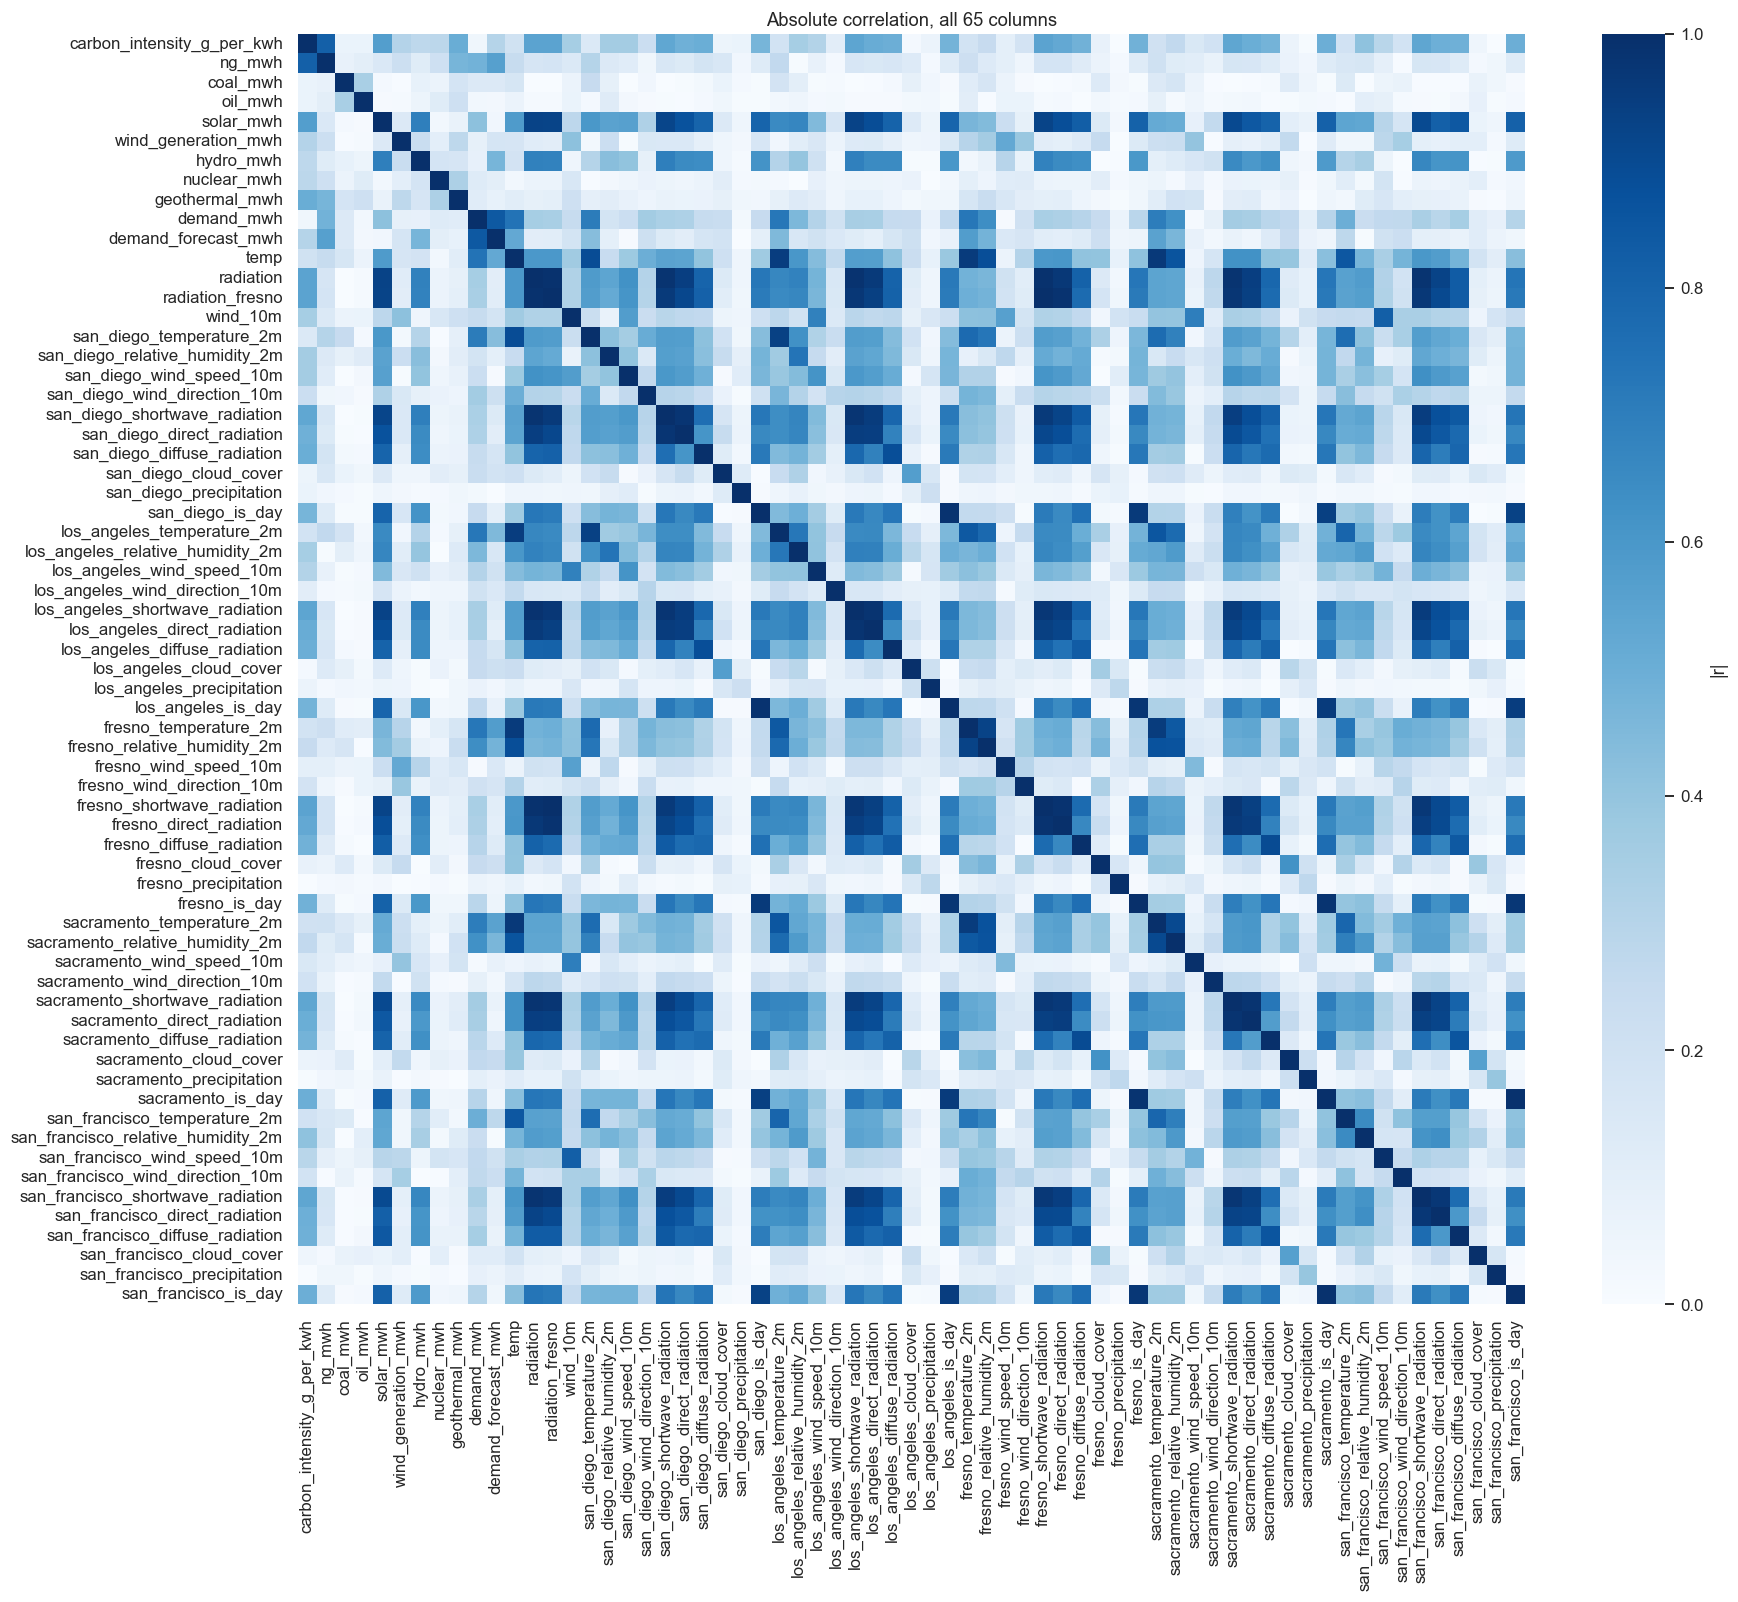

,a,b,r
0,radiation_fresno,fresno_shortwave_radiation,1.000000
1,radiation,radiation_fresno,0.989475
2,radiation,fresno_shortwave_radiation,0.989475
3,sacramento_is_day,san_francisco_is_day,0.989198
4,radiation_fresno,fresno_direct_radiation,0.986975
5,fresno_shortwave_radiation,fresno_direct_radiation,0.986975
6,radiation,los_angeles_shortwave_radiation,0.986501
7,san_diego_is_day,los_angeles_is_day,0.985024
8,los_angeles_shortwave_radiation,los_angeles_direct_radiation,0.984294
9,radiation,sacramento_shortwave_radiation,0.983835


In [3]:
fig, ax = plt.subplots(figsize=(18, 15))
sns.heatmap(raw.corr().abs(), cmap="Blues", vmin=0, vmax=1, ax=ax, cbar_kws={"label": "|r|"})
ax.set_title("Absolute correlation, all 65 columns")
plt.show()

find_correlated_pairs(raw, 0.95)

## Same-hour restatements of demand

The fuel columns are not perfectly correlated with demand, because imports cover the rest. Their sum still tracks demand, and none of them is known until the hour is over.

In [4]:
supply = raw[FUEL_COLUMNS].sum(axis=1)
print(f"correlation of total counted supply with demand: {supply.corr(raw[TARGET]):.3f}")
print(f"median share of demand covered by counted supply: {(supply / raw[TARGET]).median():.2f}")
print(f"correlation of CAISO's demand forecast with demand: {raw['demand_forecast_mwh'].corr(raw[TARGET]):.3f}")

raw.corrwith(raw[TARGET]).drop(TARGET).abs().sort_values(ascending=False).head(15).round(3)

correlation of total counted supply with demand: 0.777
median share of demand covered by counted supply: 0.71
correlation of CAISO's demand forecast with demand: 0.841


demand_forecast_mwh                 0.841
temp                                0.740
los_angeles_temperature_2m          0.725
fresno_temperature_2m               0.725
san_diego_temperature_2m            0.710
sacramento_temperature_2m           0.707
fresno_relative_humidity_2m         0.639
sacramento_relative_humidity_2m     0.628
san_francisco_temperature_2m        0.500
ng_mwh                              0.481
los_angeles_relative_humidity_2m    0.456
solar_mwh                           0.417
san_diego_wind_direction_10m        0.363
sacramento_shortwave_radiation      0.359
san_francisco_diffuse_radiation     0.350
dtype: float64

## Dropped columns and why

`demand_forecast_mwh` is not dropped. It is renamed `benchmark_caiso_forecast_mwh` and kept as the number a model has to beat, never as an input.

In [5]:
pd.set_option("display.max_colwidth", 120)
pd.Series(DROPPED, name="reason").rename_axis("column").to_frame()

,reason
column,
ng_mwh,"this hour's supply; it has to meet demand, so it restates the answer"
coal_mwh,"this hour's supply; it has to meet demand, so it restates the answer"
oil_mwh,"this hour's supply; it has to meet demand, so it restates the answer"
solar_mwh,"this hour's supply; it has to meet demand, so it restates the answer"
wind_generation_mwh,"this hour's supply; it has to meet demand, so it restates the answer"
hydro_mwh,"this hour's supply; it has to meet demand, so it restates the answer"
nuclear_mwh,"this hour's supply; it has to meet demand, so it restates the answer"
geothermal_mwh,"this hour's supply; it has to meet demand, so it restates the answer"
carbon_intensity_g_per_kwh,a formula of the fuel columns


## After the audit

The weather columns that survive, at the same hour. Wind direction is now a sine and a cosine, and sunlight is one five-city mean for total and one for diffuse light. Any pair still at 0.95 or above is dropped by `resolve_correlated`, keeping the column that tracks demand more closely.

35 weather columns after the drop list, 34 after the 0.95 rule
dropped by the 0.95 rule: {'sacramento_temperature_2m': 'correlates 0.953 with fresno_temperature_2m'}


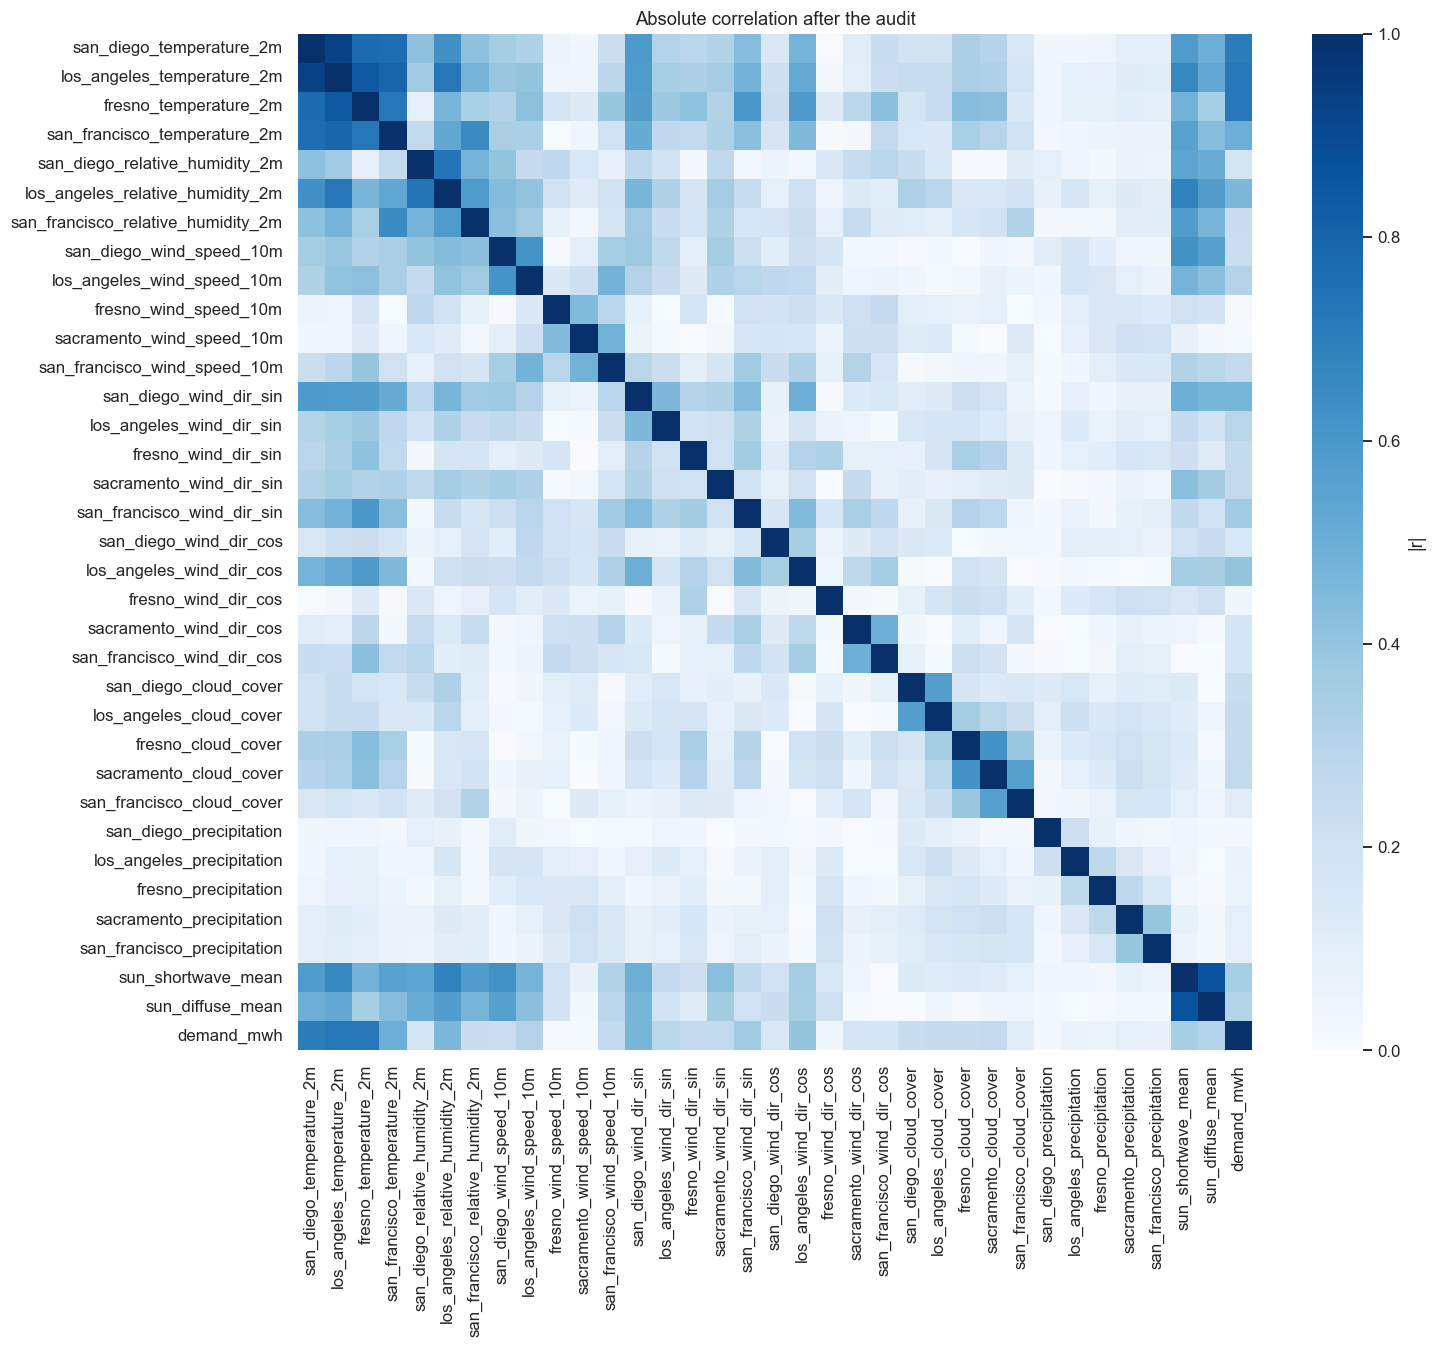

,a,b,r
0,san_diego_temperature_2m,los_angeles_temperature_2m,0.936298


In [6]:
audited = apply_audit(raw)
sources = audited[FEATURE_SOURCE_COLUMNS]
still_duplicated = resolve_correlated(sources, audited[TARGET])
kept = sources.drop(columns=list(still_duplicated))
print(f"{len(FEATURE_SOURCE_COLUMNS)} weather columns after the drop list, {kept.shape[1]} after the 0.95 rule")
print("dropped by the 0.95 rule:", still_duplicated)

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(kept.join(audited[TARGET]).corr().abs(), cmap="Blues", vmin=0, vmax=1, ax=ax, cbar_kws={"label": "|r|"})
ax.set_title("Absolute correlation after the audit")
plt.show()

review_pairs(kept)

## What still lines up with demand

Temperature is the strongest weather signal. These are same-hour correlations. The dataset builder decides whether a model sees this hour's weather or yesterday's.

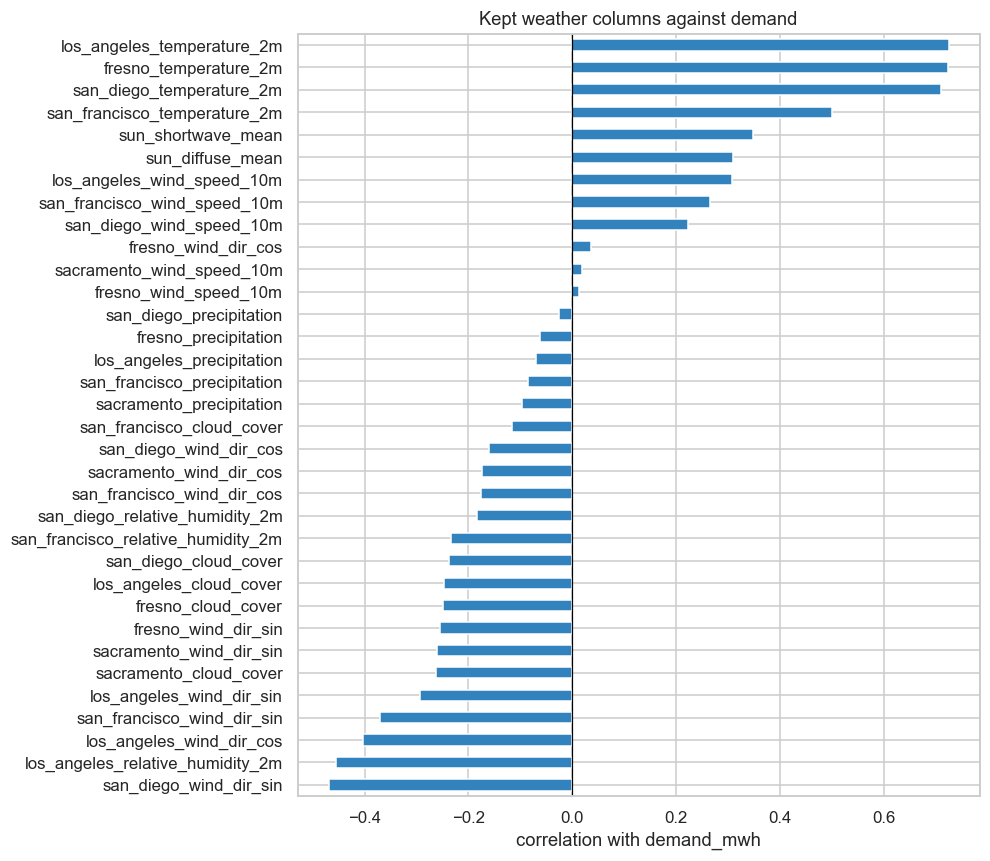

In [7]:
relevance = kept.corrwith(audited[TARGET]).sort_values()
fig, ax = plt.subplots(figsize=(8, 9))
relevance.plot.barh(ax=ax, color="#3182bd")
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("correlation with demand_mwh")
ax.set_title("Kept weather columns against demand")
plt.show()

## The other two processed tables

`location_strain_cost.csv` repeats one grid value for every location on a day, so its rows are not independent. `hourly_model_panel.csv` is the carbon notebooks' cache and keeps its own columns, because notebooks `01` to `05` depend on it.

In [8]:
location = pd.read_csv(ROOT / "data" / "processed" / "location_strain_cost.csv", parse_dates=["date"])
per_day = location.groupby("date")
print(f"{len(location)} rows, {location['date'].nunique()} days, {location['location_name'].nunique()} locations")
print(f"days where grid_strain_mwh differs between locations: {int((per_day['grid_strain_mwh'].nunique() > 1).sum())}")
print(find_correlated_pairs(location.drop(columns=["date", "location_name"]), 0.9).round(3).to_string(index=False))

panel = pd.read_csv(ROOT / "data" / "processed" / "hourly_model_panel.csv", index_col=0)
print()
print(find_correlated_pairs(panel, 0.9).round(3).to_string(index=False))

1090 rows, 218 days, 5 locations
days where grid_strain_mwh differs between locations: 0
          a            b     r
temp_mean_c   temp_max_c 0.957
   latitude    longitude 0.949
temp_mean_c   temp_min_c 0.925
    doy_cos radiation_mj 0.903

        a                b     r
radiation radiation_fresno 0.991
